# Introduction to supervised learning

Let's practice the material that was discussed during the lecture. Please, make a copy of this colaboratory in order to be able to make changes **(File -> Save a copy in Drive)**.

## Introducing Colaboratory (Colab)
**Colaboratory**, is a great tool created by Google for individuals interested in getting a hands-on experience with Machine Learning (including Deep Learning). It offers a free CPU/**GPU** quota and a preconfigured virtual machine instance set up for to run Tensorflow and Keras libraries using a Jupyter notebook instance. **In one sentence, it is a perfect “getting started” point for experimentation with neural networks for any part-time hobbist or computer nerd**.

*Introductory text by Oleg Żero (https://zerowithdot.com/colab-workspace/).*


In [7]:
!ls

sample_data


## Classification with KNN on MNIST
We shall use classical MNIST dataset to practice one of the simplest machine learning algorithms - Nearest Neighbour algorithm and its extension - K-Nearest Neighbour algorithm. MNIST stands for Mixed National Institute of Standards and Technology and contains almost 60000 small square 28×28 pixel grayscale images of digits from 0 to 9. Let's load it!

### Setup:
Here we will load necessary libraries (NumPy and Pandas) and MNIST dataset

In [8]:
import numpy as np # for matrix stuff
import pandas as pd # to work with datasets
import matplotlib.pyplot as plt # subjectively ugly plotting here
from seaborn import countplot # a bit less ugly plotting

Getting MNIST dataset from Keras library

In [9]:
from tensorflow.keras.datasets import mnist
(images, labels),(_, _) = mnist.load_data()

11490434/11490434 [==============================] - 0s 0us/step


In [10]:
#images = images / 255 # normalising images

We check the dimensionality of the downloaded images:

In [11]:
print(f"images are of shape: {images.shape} and labels: {labels.shape}")

images are of shape: (60000, 28, 28) and labels: (60000,)


### Visualising MNIST

Let's look into the first image:

In [12]:
print(images[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 18

That was not super helpful, can we make it more human friendly?

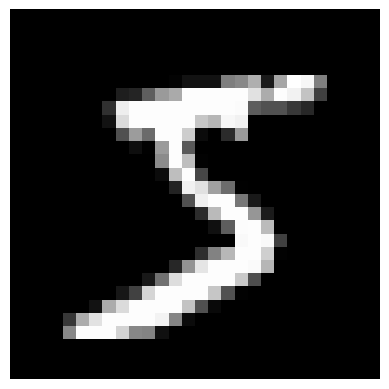

In [13]:
plt.imshow(images[0], plt.get_cmap('gray'));
plt.axis('off')
plt.show()

What is the label of this image?

In [14]:
print (f"Correct label of the first image is: {labels[0]}")

Correct label of the first image is: 5


### Subsampling

Although, in practice you typically want to use as much data as possible to train your models, large datasets are not very suitable for experimenting and visualization -- it is just too annoying to have to wait minutes for each step to continue. Thus, 60000 examples is a bit too much for our purposes, so why not to sample just 2000.

In [15]:
train_images = images[:2000]
train_labels = labels[:2000]

# images that our system will be validated with
test_images = images[2000:3000]
test_labels = labels[2000:3000]

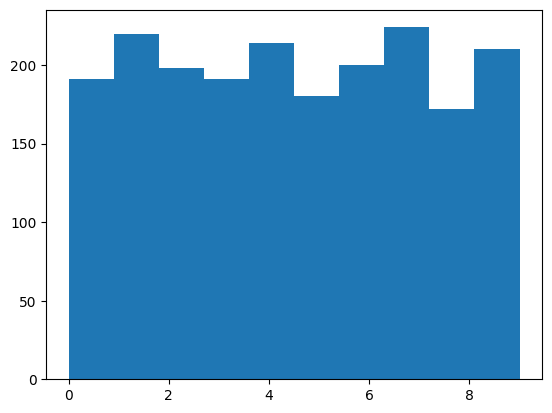

In [16]:
# We should make sure that the distribution is more or less uniform across our samples
plt.hist(train_labels)
plt.show()

<Axes: ylabel='count'>

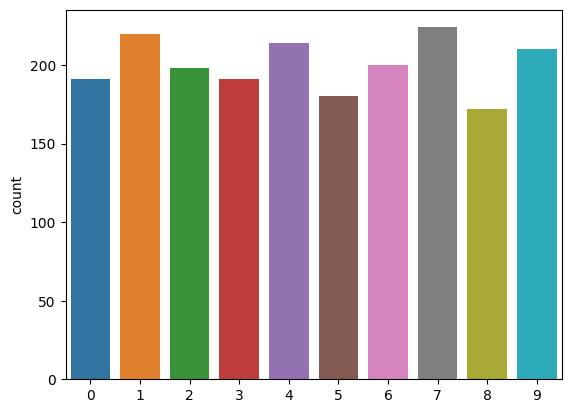

In [17]:
countplot(x=train_labels) # it looks better than matplotlib histogram

Let's see some more examples from all classes.

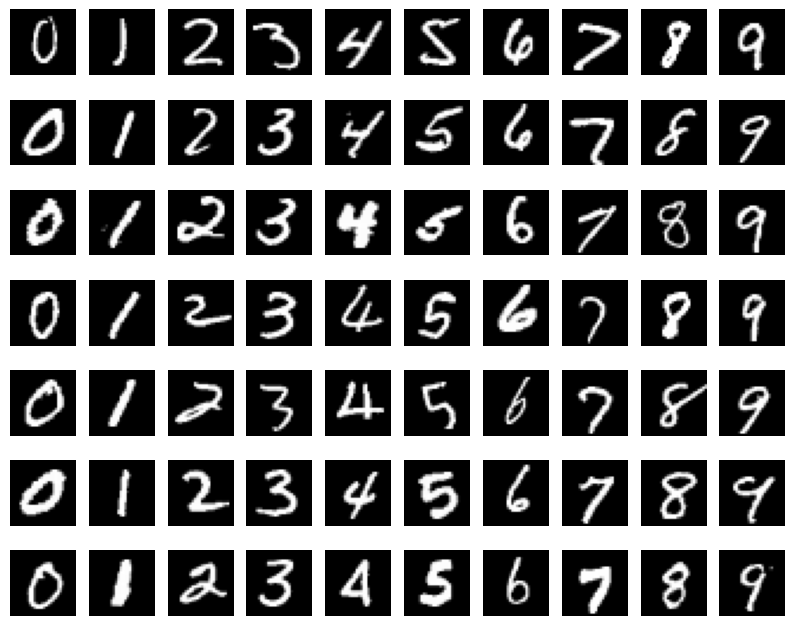

In [18]:
# "Names" of classes:
classes =  ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

num_classes = len(classes)
samples_per_class = 7
fig, axs = plt.subplots(samples_per_class, num_classes, figsize=(10.0, 8.0))

for i in range(num_classes):
  # select ids of images that correspond to given class
  idxs = np.flatnonzero(train_labels == i)

  # select a random subset of size samples_per_class
  idxs = np.random.choice(idxs, samples_per_class, replace=False)

  # visualise
  for j, id in enumerate(idxs):
    axs[j, i].imshow(train_images[id], cmap='gray')
    axs[j, i].axis('off')
plt.show()

### Implementing the Nearest Neighbour algorithm

The algorithm consists of the following three steps:
1. Compute distances to all points in the dataset;
2. Find the closest point;
3. Report the corresponding label.

We should start with defining the distance function.

**Classroom exercise**: Let's define a distance function, let it be Eucledian distance ($L_2$)

$$L_2 = \sqrt{\sum{(x_1 - x_2)^2}}$$



In [19]:
def dist(img1, img2):
  ##### YOUR CODE STARTS #####
  return np.sqrt(np.sum((img1 - img2)**2))
  ##### YOUR CODE ENDS #####

Check the validity of the function here:

In [20]:
print(f"Distance between first two images is {dist(train_images[0], train_images[1])} and should be about 9.36")

Distance between first two images is 140.3923074815711 and should be about 9.36


You can play with the defined function below. Check that the distance between images of the same digit is typically smaller than the distance between images of different digits.

In [21]:
print(f"Distance between two images with the same class ({train_labels[3]} and {train_labels[6]}) is {dist(train_images[3], train_images[6])}")
print(f"Distance between two images with different classes ({train_labels[0]} and {train_labels[1]}) is {dist(train_images[0], train_images[1])}")

Distance between two images with the same class (1 and 1) is 103.54226190305097
Distance between two images with different classes (5 and 0) is 140.3923074815711


Let's remind us the steps of the NN algorithm:

1. Compute distances to all points in the dataset;
2. Find the closest point;
3. Report the corresponding label.

Now that we know the distance function, we can build the rest of the algorithm.

**Classroom exercise**: Implement the three steps.

We shall do it gently. First we pick a sample image that we will be classifying. Let us say that the first image from the `test_images` is an unknown image sent by our friend:

In [22]:
# an unseen image
test_image = test_images[1]
test_label = test_labels[1]

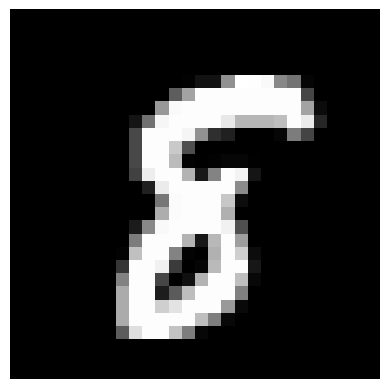

In [23]:
plt.imshow(test_image, plt.get_cmap('gray'));
plt.axis('off')
plt.show()

**Classroom exercise:** compute all distances from the `test_image` to the `train_images` in the dataset

In [24]:
all_distances = np.zeros(train_images.shape[0])
all_distances


array([0., 0., 0., ..., 0., 0., 0.])

In [25]:
##### YOUR CODE STARTS #####
# for loop style
all_distances = np.zeros(train_images.shape[0])
for i,image in enumerate(train_images):
  all_distances[i] = dist(image, test_image)
print(all_distances[:5])

# list comprehension version
# [<expression with element> for <element> in <list/array>]
all_distances = [dist(test_image, train_image) for train_image in train_images]
print(all_distances[:5])
##### YOUR CODE ENDS #####

[131.64725595 139.40229553 135.44371525 117.2561299  129.87686476]
[131.64725595317208, 139.40229553346674, 135.4437152473307, 117.25612990372828, 129.87686476043376]


Now let's find out which image is closest to our `test_image`

In [26]:
np.min(all_distances)

97.73944955850733

In [27]:
i = np.argmin(all_distances)
print(i)

1388


Almost done, now report a label with index `i` in `train_labels`

In [28]:
predicted_label = train_labels[i]

Compare it to the true label of the first image in the `train_labels`

In [29]:
print(f"Predicted class for the first image is {predicted_label} and the true label is {test_label}")

Predicted class for the first image is 8 and the true label is 8


Here we can visualise the nearest in terms of the Eucledian distance image from the `train_images`

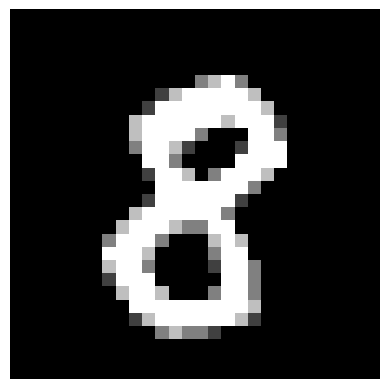

In [30]:
plt.imshow(train_images[i], plt.get_cmap('gray'));
plt.axis('off')
plt.show()

**Classroom exercise:** Now we should make a function out of the code we have already written.

In [31]:
def classify(image, train_images, train_labels):
  ##### YOUR CODE STARTS #####
  all_distances = [dist(image, train_image) for train_image in train_images]
  prediction =  train_labels[np.argmin(all_distances)]
  ##### YOUR CODE ENDS #####
  return prediction

Let's test this function to verify that it works

In [32]:
print(f"Predicted class for the first image is {classify(test_image, train_images, train_labels)} and the true label is {test_label}")

Predicted class for the first image is 8 and the true label is 8


**Classroom exercise:** Classify all test images and store them into a separate variable `test_predicted`.

In [33]:
##### YOUR CODE STARTS #####
test_predicted = [classify(test_image, train_images, train_labels) for test_image in test_images]
# This will take time, why?
##### YOUR CODE ENDS #####

How many instances from the test set the classifier has predicted correctly?

In [34]:
np.sum(test_labels == test_predicted)

238

In [35]:
n_correct = np.sum(test_labels == test_predicted)
print(f"Number of correctly predicted images is {n_correct}")

Number of correctly predicted images is 238


Now we will use **`accuracy`** (namely, proportion of correctly guessed classes) to estimate the performance of our nearest neighbor classifier. For that we need to divide number of correctly predicted images by total number of images.

In [36]:
nn_accuracy = n_correct/len(test_labels)
print(f"Final accuracy of our nearest neighbor classifier is {nn_accuracy}. Not bad!")

Final accuracy of our nearest neighbor classifier is 0.238. Not bad!


Let's examine some of the missclassified examples.


This image with 8 was incorrectly predicted as 4


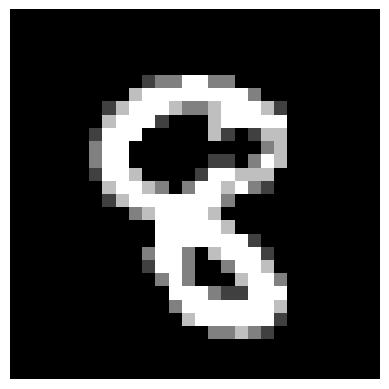

In [37]:
misclassified = np.flatnonzero(test_predicted != test_labels)

# Set an index of misclassified instance you want to examine
index = 1

# Plot this instance as usual
img_matrix = test_images[misclassified[index]].reshape((28, 28))
plt.imshow(img_matrix, plt.get_cmap('gray'))
plt.axis('off')
print(f"This image with {test_labels[misclassified[index]]} was incorrectly predicted as {test_predicted[misclassified[index]]}")

### Scikit-learn

Now let us use the Scikit-Learn package to train the Nearest Neigbor classifier.

Most of the models that we are going to use are implemented in scikit-learn, for example KNN is available under the name `KNNeiborsClassifier`. All you need to do is to import it from `sklearn` (this a short name for scikit-learn).

In [6]:
import sklearn
from sklearn.neighbors import KNeighborsClassifier

Let's create an instance of the NN classifier by calling a `KNeighborsClassifier()` class. By default it produces a KNN classifier that we have discussed in the lecture. As an input parameter you can specify `k`. For example 10 nearest neighbour classifier is created like this:

In [38]:
model = KNeighborsClassifier(n_neighbors = 10)
# what should be a value of k to produce NN classifier?

Most of the scikit-learn models have method `fit` that let you train the classifier given training instances and correct labels:

In [39]:
model.fit(train_images.reshape(2000, 28*28), train_labels)

KNeighborsClassifier(n_neighbors=10)

**Classroom exercise:** Use trained nearest neighbor classifier (`model`) to predict `test_images` and then calculate the accuracy. How does it compare to the one we obtained in the class?

In [56]:
# train_images.reshape(2000, 28*28)
train_idx = 44
test_predictions_sk = model.predict(test_images.reshape(len(test_images),28*28))
matches = np.sum(test_predictions_sk == test_labels)
accuracy = matches / len(test_labels)
print(f"Accuracy {accuracy}")

Accuracy 0.902


In [ ]:
##### YOUR CODE STARTS #####
test_predicted = model.predict(test_images.reshape(1000, 28*28))
n_correct = np.sum(test_labels == test_predicted)
##### YOUR CODE ENDS #####
print(f"Number of correctly predicted images is {n_correct}")

Number of correctly predicted images is 902
